In [1]:
import os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
DATA_NAME = "digikala-comments.csv"
DATA_PATH = Path(os.path.join("..","data","raw" , DATA_NAME))

print("The current file location : ",DATA_PATH.cwd())
print("File exists:", DATA_PATH.exists())

if DATA_PATH.exists():
    print("File size:", round(os.path.getsize(DATA_PATH) / 1024**3, 2), "GB")

The current file location :  d:\Projects\python projects\boot_camp_HW\project 3\notebooks
File exists: True
File size: 1.19 GB


In [3]:
df_sample = pd.read_csv(
    DATA_PATH,
    nrows=10
)

print(df_sample.shape)
print(df_sample.columns.tolist())

print("\nData types:")
print(df_sample.dtypes)

display(df_sample.head())

(10, 15)
['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']

Data types:
id                         int64
title                        str
body                         str
created_at                   str
rate                     float64
recommendation_status        str
is_buyer                    bool
product_id                 int64
advantages                   str
disadvantages                str
likes                      int64
dislikes                   int64
seller_title                 str
seller_code                  str
true_to_size_rate        float64
dtype: object


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


Total records: 6,156,289
Unique products: 331,599
Unique sellers: 29,213

Reviews per product:


,reviews_per_product
count,331599.000000
mean,18.565463
std,40.934097
min,1.000000
25%,1.000000
50%,4.000000
75%,13.000000
90%,46.000000
95%,110.000000
99%,200.000000



Product review count distribution:


,number_of_products,percentage
reviews_per_product,,
1,91944,27.73
2-5,106514,32.12
6-10,40804,12.31
11-50,61287,18.48
51-100,13146,3.96
100+,17904,5.40


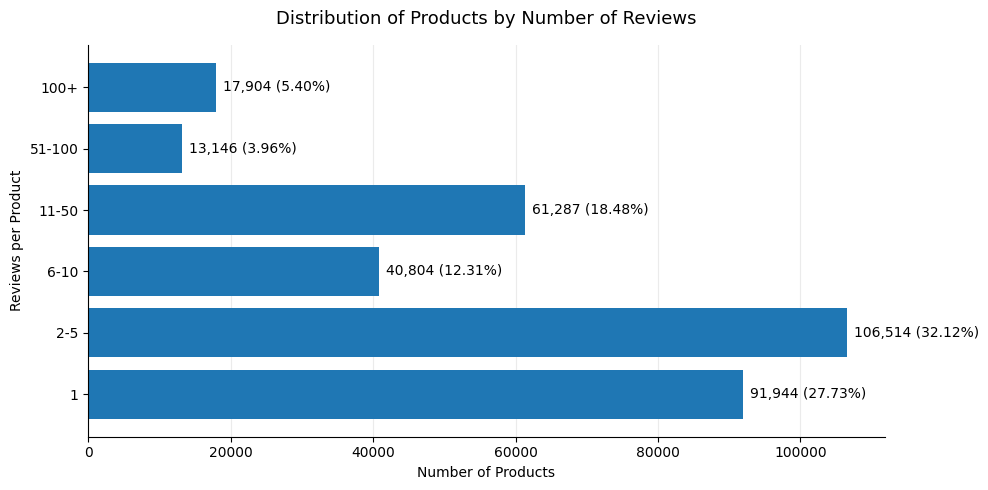

In [4]:
chunksize = 100_000

total_rows = 0
unique_products = set()
unique_sellers = set()

# تعداد نظرات هر محصول
product_review_counts = Counter()

for chunk in pd.read_csv(DATA_PATH, chunksize=chunksize):

    total_rows += len(chunk)

    unique_products.update(
        chunk["product_id"].dropna().unique()
    )

    unique_sellers.update(
        chunk["seller_code"].dropna().unique()
    )

    product_review_counts.update(
        chunk["product_id"].value_counts().to_dict()
    )

# -------------------------------
# General dataset information
# -------------------------------

print(f"Total records: {total_rows:,}")
print(f"Unique products: {len(unique_products):,}")
print(f"Unique sellers: {len(unique_sellers):,}")

# ------------------------------
# Reviews per product statistics
# ------------------------------

review_counts = pd.Series(
    list(product_review_counts.values()),
    name="reviews_per_product"
)

print("\nReviews per product:")

display(
    review_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame()
)

# -------------------------------
# Product review count distribution
# -------------------------------

bins = [0, 1, 5, 10, 50, 100, float("inf")]

labels = [
    "1",
    "2-5",
    "6-10",
    "11-50",
    "51-100",
    "100+"
]

distribution = (
    pd.cut(
        review_counts,
        bins=bins,
        labels=labels
    )
    .value_counts()
    .sort_index()
)

# Create a complete summary table
product_distribution = distribution.rename(
    "number_of_products"
).to_frame()

product_distribution["percentage"] = (
    product_distribution["number_of_products"]
    / len(review_counts) * 100
).round(2)

print("\nProduct review count distribution:")
display(product_distribution)

# -------------------------------
# Visualization
# -------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    product_distribution.index.astype(str),
    product_distribution["number_of_products"]
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({percentage:.2f}%)"
        for count, percentage in zip(
            product_distribution["number_of_products"],
            product_distribution["percentage"]
        )
    ],
    padding=5
)

ax.set_title(
    "Distribution of Products by Number of Reviews",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Number of Products")
ax.set_ylabel("Reviews per Product")

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## A part2

In [5]:
missing_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(DATA_PATH, chunksize=100_000):

    chunk_missing = chunk.isna().sum()

    missing_counts = missing_counts.add(
        chunk_missing,
        fill_value=0
    )

missing_counts = missing_counts.astype("int64")

missing_report = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (
        missing_counts / total_rows * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_report)

,missing_count,missing_percentage
true_to_size_rate,6065516,98.53
disadvantages,5744017,93.30
advantages,5448084,88.50
title,2865062,46.54
recommendation_status,894426,14.53
seller_title,302181,4.91
seller_code,302181,4.91
body,637,0.01
id,0,0.00
dislikes,0,0.00


## A part3

In [6]:
df = pd.read_csv(DATA_PATH)
print(df["rate"].value_counts().sort_index())

print(
    df["rate"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

rate
0.00        529098
0.05            97
0.10            66
0.15           181
0.20           661
            ...   
4.85          1476
4.88             2
4.90           426
5.00       2398801
2500.00          1
Name: count, Length: 178, dtype: int64
rate
0.00        8.594431
0.05        0.001576
0.10        0.001072
0.15        0.002940
0.20        0.010737
             ...    
4.85        0.023975
4.88        0.000032
4.90        0.006920
5.00       38.965049
2500.00     0.000016
Name: proportion, Length: 178, dtype: float64


In [7]:
print(
    df["rate"]
    .value_counts()
    .sort_index(ascending=False)
    .head(20)
)
print("\n====================================\n")
print("finding outlayers:")
print(df[df["rate"] > 5][["rate", "body"]])

rate
2500.00          1
5.00       2398801
4.90           426
4.88             2
4.85          1476
4.80          7276
4.79             5
4.75          8292
4.73             1
4.71            13
4.70          3682
4.67           154
4.65          2869
4.64             7
4.63             1
4.60          8152
4.57             9
4.56             1
4.55          1111
4.50         13479
Name: count, dtype: int64


finding outlayers:
           rate             body
4369260  2500.0  کوچک و با کیفیت


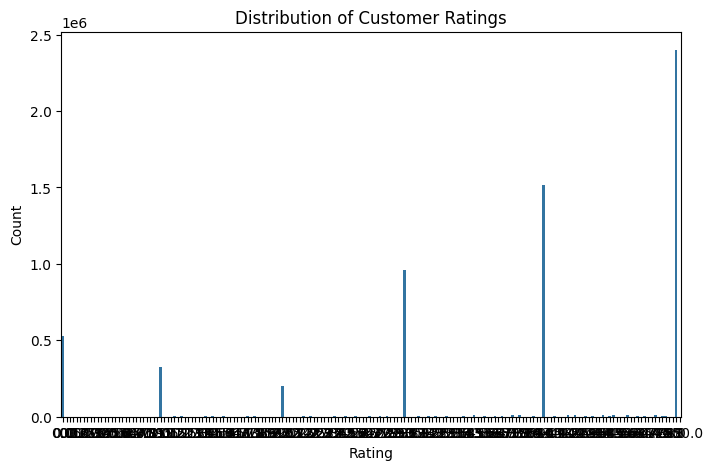

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rate",
    order=sorted(df["rate"].dropna().unique())
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")

plt.show()

In [9]:
print("Unique values:", df["rate"].nunique())
print(df["rate"].value_counts().head(20))
print(df["rate"].describe())

Unique values: 178
rate
5.00    2398801
4.00    1515723
3.00     958799
0.00     529098
1.00     327662
2.00     198077
4.50      13479
3.50      12207
4.25      11653
3.75      10045
4.20       9843
3.80       8745
4.40       8675
4.75       8292
4.60       8152
3.25       7695
4.80       7276
3.40       7250
3.60       6975
2.50       5438
Name: count, dtype: int64
count    6.156289e+06
mean     3.648286e+00
std      1.861854e+00
min      0.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      5.000000e+00
max      2.500000e+03
Name: rate, dtype: float64


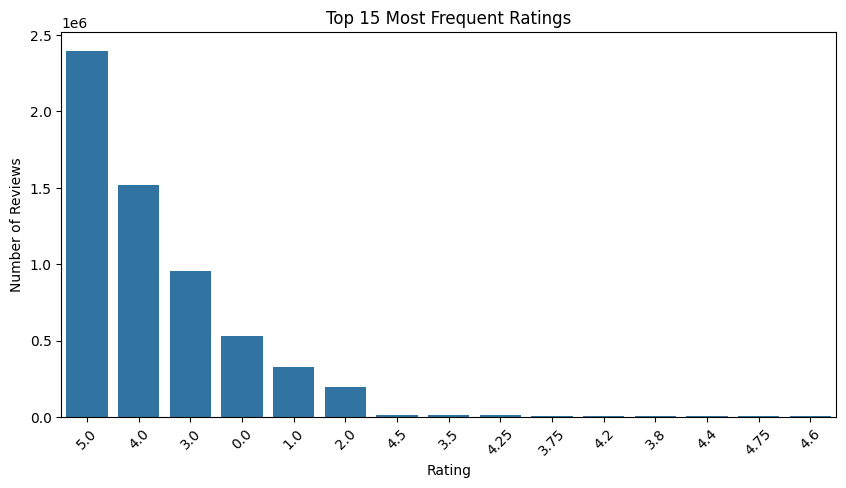

total rated coments : 6019251


In [10]:
rate_counts = df["rate"].value_counts()

rate_counts = rate_counts.drop(2500, errors="ignore")

top_rates = rate_counts.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_rates.index.astype(str),
    y=top_rates.values
)

plt.title("Top 15 Most Frequent Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)

plt.show()

print("total rated coments :",top_rates.values.sum())

In [11]:
print(df["rate"].dtype)
print(df["rate"].min())
print(df["rate"].max())
print(df["rate"].nunique())
print(df["rate"].describe())



# Create a copy without the outlier
df_without_outlier = df[df["rate"] != 2500].copy()

# Compare statistics
for name, data in [
    ("Original Data", df),
    ("Without Outlier", df_without_outlier)
]:
    print(f"\n{'=' * 40}")
    print(name)
    print("=" * 40)

    print("dtype:", data["rate"].dtype)
    print("min:", data["rate"].min())
    print("max:", data["rate"].max())
    print("nunique:", data["rate"].nunique())
    print(data["rate"].describe())

float64
0.0
2500.0
178
count    6.156289e+06
mean     3.648286e+00
std      1.861854e+00
min      0.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      5.000000e+00
max      2.500000e+03
Name: rate, dtype: float64

Original Data
dtype: float64
min: 0.0
max: 2500.0
nunique: 178
count    6.156289e+06
mean     3.648286e+00
std      1.861854e+00
min      0.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      5.000000e+00
max      2.500000e+03
Name: rate, dtype: float64

Without Outlier
dtype: float64
min: 0.0
max: 5.0
nunique: 177
count    6.156288e+06
mean     3.647880e+00
std      1.566601e+00
min      0.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      5.000000e+00
max      5.000000e+00
Name: rate, dtype: float64


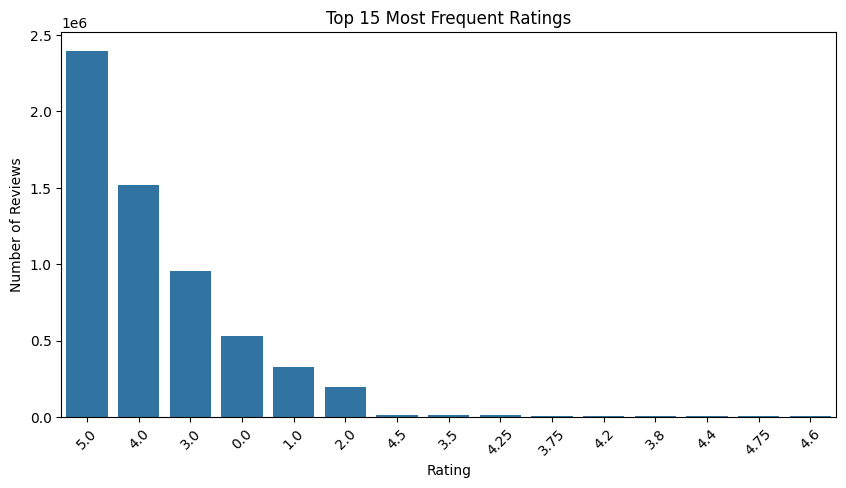

total rated coments : 6019251


In [12]:
rate_counts = df["rate"].value_counts()

rate_counts = rate_counts.drop(2500, errors="ignore")

top_rates = rate_counts.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_rates.index.astype(str),
    y=top_rates.values
)

plt.title("Top 15 Most Frequent Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)

plt.show()

print("total rated coments :",top_rates.values.sum())

In [13]:
print("out layers rates")
print(df.loc[
    (df["rate"] < 0) | (df["rate"] > 5),
    "rate"
].value_counts())
df.loc[df["rate"] == 2500]

out layers rates
rate
2500.0    1
Name: count, dtype: int64


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
4369260,38631814,زیبا,کوچک و با کیفیت,9 شهریور 1401,2500.0,recommended,True,5095301,NaN,NaN,0,0,مستر راد,A4Z54,NaN


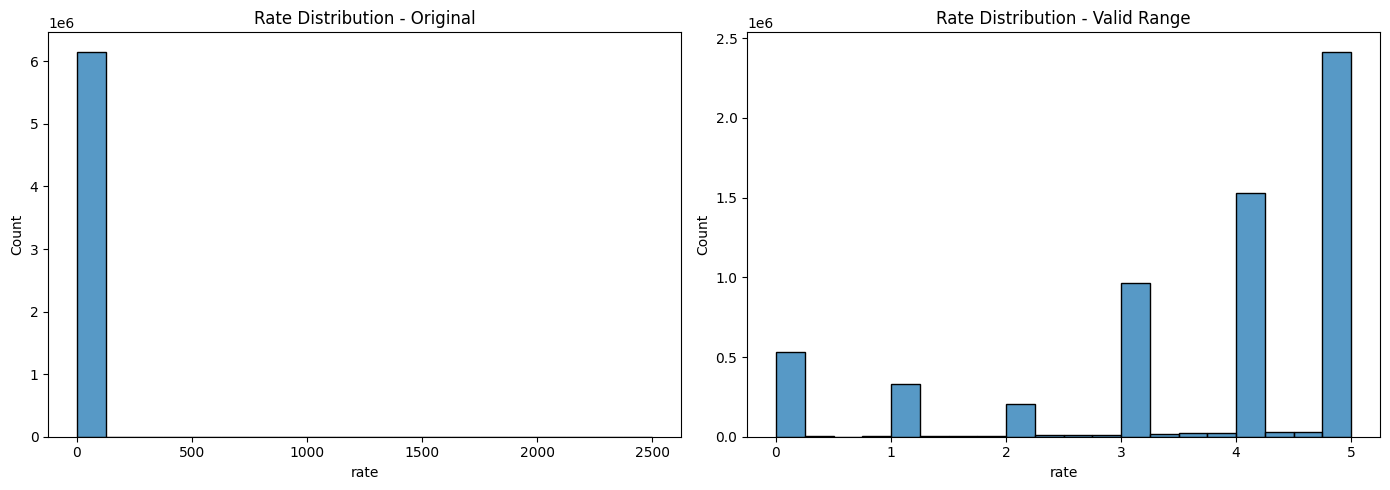

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["rate"].dropna(),
    bins=20,
    ax=axes[0]
)
axes[0].set_title("Rate Distribution - Original")

sns.histplot(
    df.loc[df["rate"].between(0, 5), "rate"],
    bins=20,
    ax=axes[1]
)
axes[1].set_title("Rate Distribution - Valid Range")

plt.tight_layout()
plt.show()

In [15]:
# Frequency
counts = df["recommendation_status"].value_counts(dropna=False)

# Percentage
percentages = df["recommendation_status"].value_counts(
    normalize=True,
    dropna=False
) * 100

# Statistics - Original Data
stats = df.groupby(
    "recommendation_status",
    dropna=False
)["rate"].agg(
    mean="mean",
    median="median",
    std="std"
)

# Statistics - Valid Ratings (0 to 5)
valid_stats = df[df["rate"].between(0, 5)].groupby(
    "recommendation_status",
    dropna=False
)["rate"].agg(
    valid_count="count",
    valid_mean="mean",
    valid_median="median",
    valid_std="std"
)

# Combine results
result = pd.concat(
    [
        counts.rename("count"),
        percentages.rename("percentage"),
        stats,
        valid_stats
    ],
    axis=1
)

# Add total row
result.loc["TOTAL"] = {
    "count": counts.sum(),
    "percentage": percentages.sum(),
    "mean": df["rate"].mean(),
    "median": df["rate"].median(),
    "std": df["rate"].std(),
    "valid_count": df["rate"].between(0, 5).sum(),
    "valid_mean": df.loc[df["rate"].between(0, 5), "rate"].mean(),
    "valid_median": df.loc[df["rate"].between(0, 5), "rate"].median(),
    "valid_std": df.loc[df["rate"].between(0, 5), "rate"].std()
}

# Display
result.round(2)

,count,percentage,mean,median,std,valid_count,valid_mean,valid_median,valid_std
recommendation_status,,,,,,,,,
recommended,4162839,67.62,3.93,4.0,1.94,4162838,3.93,4.0,1.51
NaN,894426,14.53,4.04,4.0,1.28,894426,4.04,4.0,1.28
no_idea,594121,9.65,2.92,3.0,0.91,594121,2.92,3.0,0.91
not_recommended,504903,8.20,1.45,1.0,0.98,504903,1.45,1.0,0.98
TOTAL,6156289,100.00,3.65,4.0,1.86,6156288,3.65,4.0,1.57


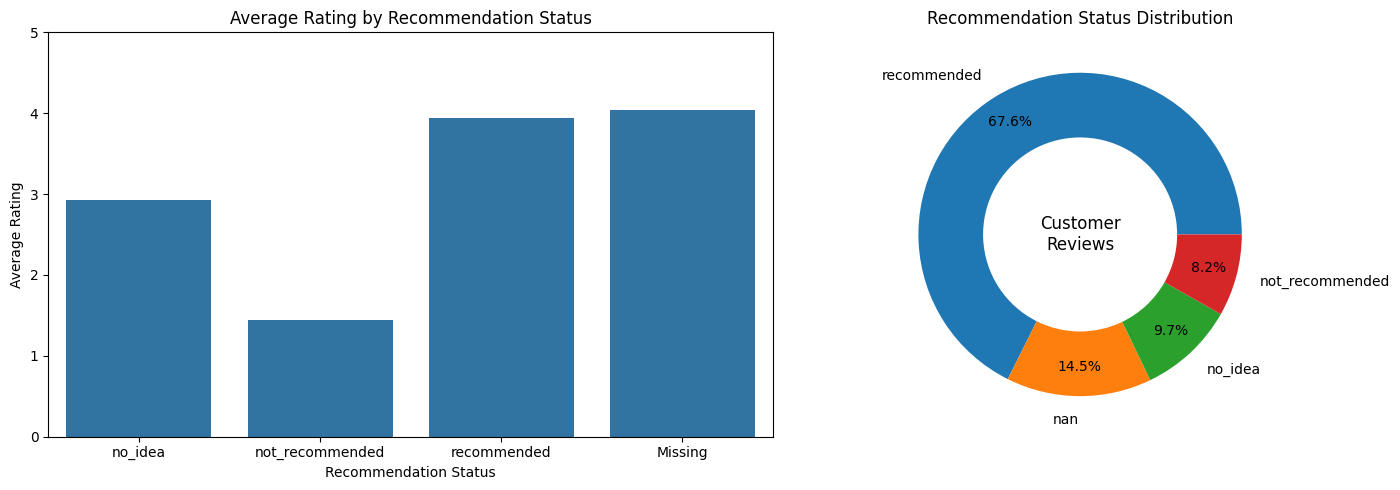

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Calculate summary
summary_df = df.groupby(
    "recommendation_status",
    dropna=False
)["rate"].mean().reset_index()

summary_df["recommendation_status"] = (
    summary_df["recommendation_status"].fillna("Missing")
)

# Average Rating
sns.barplot(
    data=summary_df,
    x="recommendation_status",
    y="rate",
    ax=axes[0]
)

axes[0].set_title("Average Rating by Recommendation Status")
axes[0].set_xlabel("Recommendation Status")
axes[0].set_ylabel("Average Rating")
axes[0].set_ylim(0, 5)

# Distribution
status_counts = df["recommendation_status"].value_counts(
    normalize=True,
    dropna=False
) * 100

status_counts.index = status_counts.index.astype(str)

axes[1].pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    wedgeprops={"width": 0.4},
    pctdistance=0.82,
    labeldistance=1.15
)

axes[1].set_title("Recommendation Status Distribution")


axes[1].text(
    0, 0,
    "Customer\nReviews",
    ha="center",
    va="center",
    fontsize=12
)

plt.tight_layout()
plt.show()

In [17]:
# Keep valid ratings
valid_df = df[df["rate"].between(0, 5)].copy()

# Cross-tabulation
rating_recommendation = pd.crosstab(
    valid_df["rate"],
    valid_df["recommendation_status"],
    normalize="index"
) * 100

print(rating_recommendation.round(2))

rating_counts = pd.crosstab(
    valid_df["rate"],
    valid_df["recommendation_status"]
)

rating_counts

recommendation_status  no_idea  not_recommended  recommended
rate                                                        
0.00                      4.08            11.40        84.52
0.05                     10.64            86.17         3.19
0.10                     27.42            64.52         8.06
0.15                     43.93            16.18        39.88
0.20                      5.79            42.98        51.23
...                        ...              ...          ...
4.80                      1.74             0.38        97.88
4.85                      1.39             0.39        98.22
4.88                      0.00             0.00       100.00
4.90                      1.34             0.27        98.39
5.00                      0.75             0.32        98.93

[171 rows x 3 columns]


recommendation_status,no_idea,not_recommended,recommended
rate,,,
0.00,20570,57424,425745
0.05,10,81,3
0.10,17,40,5
0.15,76,28,69
0.20,33,245,292
...,...,...,...
4.80,109,24,6135
4.85,18,5,1271
4.88,0,0,2


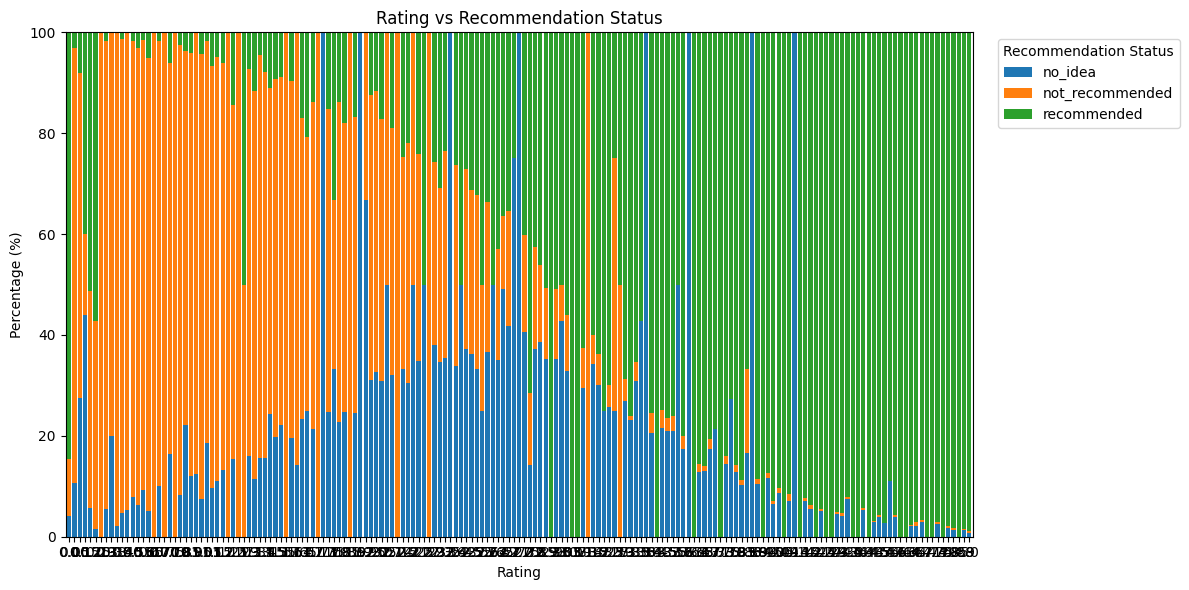

In [18]:
# Calculate percentage distribution
rating_recommendation = pd.crosstab(
    valid_df["rate"],
    valid_df["recommendation_status"],
    normalize="index"
) * 100

# Plot
ax = rating_recommendation.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Rating vs Recommendation Status")
ax.set_xlabel("Rating")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)
plt.legend(
    title="Recommendation Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [19]:
# Frequency
counts = df["is_buyer"].value_counts(dropna=False)

# Percentage
percentages = df["is_buyer"].value_counts(
    normalize=True,
    dropna=False
) * 100

# Rating Statistics (Valid Ratings)
valid_df = df[df["rate"].between(0, 5)]

stats = valid_df.groupby(
    "is_buyer",
    dropna=False
)["rate"].agg(
    valid_count="count",
    mean_rate="mean",
    median_rate="median",
    std_rate="std"
)

# Recommendation Status Distribution
recommendation = pd.crosstab(
    df["is_buyer"],
    df["recommendation_status"],
    normalize="index",
    dropna=False
) * 100

recommendation.columns = [
    f"recommendation_{col}"
    for col in recommendation.columns
]

# Combine all results
buyer_analysis = pd.concat(
    [
        counts.rename("count"),
        percentages.rename("percentage"),
        stats,
        recommendation
    ],
    axis=1
)

# Add TOTAL row
buyer_analysis.loc["TOTAL"] = {
    "count": counts.sum(),
    "percentage": percentages.sum(),
    "valid_count": valid_df["rate"].count(),
    "mean_rate": valid_df["rate"].mean(),
    "median_rate": valid_df["rate"].median(),
    "std_rate": valid_df["rate"].std(),
    **recommendation.mul(counts, axis=0).sum().div(counts.sum()).to_dict()
}

# Display
buyer_analysis.round(2)

,count,percentage,valid_count,mean_rate,median_rate,std_rate,recommendation_no_idea,recommendation_not_recommended,recommendation_recommended,recommendation_nan
is_buyer,,,,,,,,,,
True,5854108,95.09,5854107,3.63,4.0,1.57,10.15,8.62,71.11,10.12
False,302181,4.91,302181,4.05,5.0,1.38,0.00,0.00,0.00,100.00
TOTAL,6156289,100.00,6156288,3.65,4.0,1.57,9.65,8.20,67.62,14.53


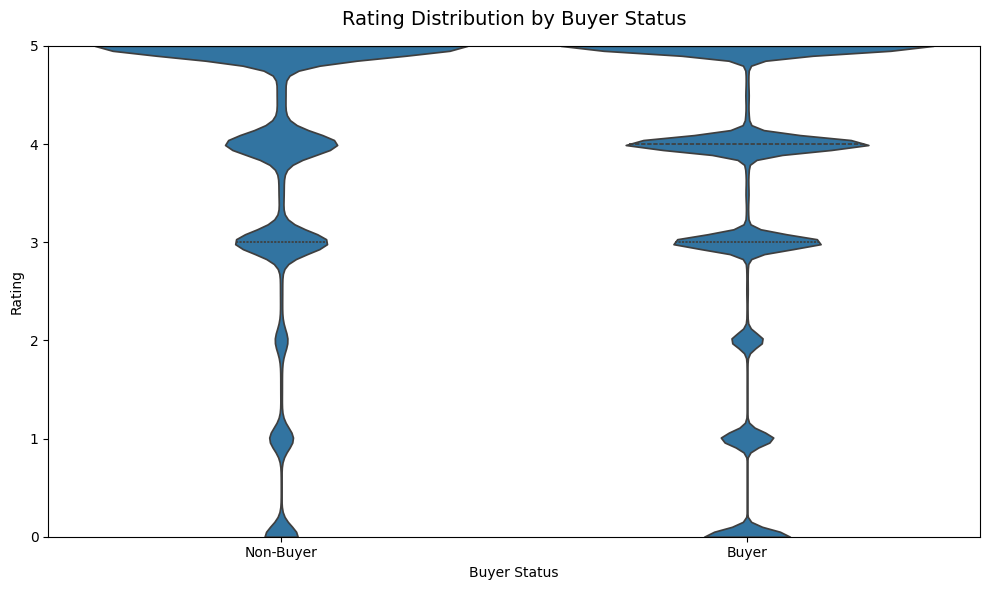

In [20]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df[df["rate"].between(0, 5)],
    x="is_buyer",
    y="rate",
    inner="quartile",
    cut=0,
    density_norm="width"
)

plt.title(
    "Rating Distribution by Buyer Status",
    fontsize=14,
    pad=15
)

plt.xlabel("Buyer Status")
plt.ylabel("Rating")

plt.xticks(
    [0, 1],
    ["Non-Buyer", "Buyer"]
)

plt.ylim(0, 5)
plt.tight_layout()
plt.show()

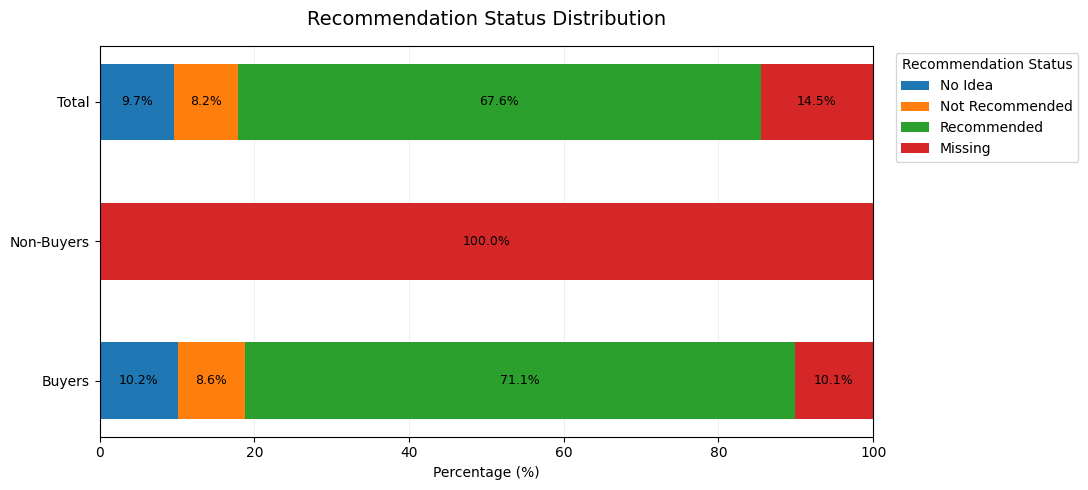

In [21]:
groups = ["Buyers", "Non-Buyers", "Total"]

data = {
    "No Idea": [10.15, 0, 9.65],
    "Not Recommended": [8.62, 0, 8.20],
    "Recommended": [71.11, 0, 67.62],
    "Missing": [10.12, 100, 14.53]
}

fig, ax = plt.subplots(figsize=(11, 5))

left = np.zeros(len(groups))

for label, values in data.items():
    ax.barh(groups, values, left=left, label=label, height=0.55)

    for i, value in enumerate(values):
        if value >= 7:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9
            )

    left += np.array(values)

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage (%)")
ax.set_title("Recommendation Status Distribution", fontsize=14, pad=15)

ax.legend(
    title="Recommendation Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## A part 4 : Body

In [22]:
# Calculate review length
text_df = df[["id", "product_id", "title", "body", "rate"]].copy()

text_df["review_length"] = (
    text_df["body"].fillna("").str.len()
)
# Basic statistical summary
text_df.describe()

,id,product_id,rate,review_length
count,6.156289e+06,6.156289e+06,6.156289e+06,6.156289e+06
mean,3.704709e+07,3.908983e+06,3.648286e+00,4.839334e+01
std,1.393243e+07,3.015881e+06,1.861854e+00,6.434920e+01
min,9.815860e+05,7.602000e+03,0.000000e+00,0.000000e+00
25%,2.731234e+07,1.532375e+06,3.000000e+00,1.500000e+01
50%,4.044773e+07,3.183184e+06,4.000000e+00,2.900000e+01
75%,4.897122e+07,5.992988e+06,5.000000e+00,5.700000e+01
max,5.474516e+07,1.270221e+07,2.500000e+03,4.000000e+03


In [23]:
# Empty reviews
empty_reviews = (text_df["review_length"] == 0).sum()

empty_percentage = empty_reviews / len(text_df) * 100

print(f"Empty reviews: {empty_reviews:,}")
print(f"Percentage: {empty_percentage:.4f}%")

# Upper percentiles
text_df["review_length"].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

Empty reviews: 637
Percentage: 0.0103%


0.900    106.0
0.950    152.0
0.990    297.0
0.995    381.0
0.999    654.0
Name: review_length, dtype: float64

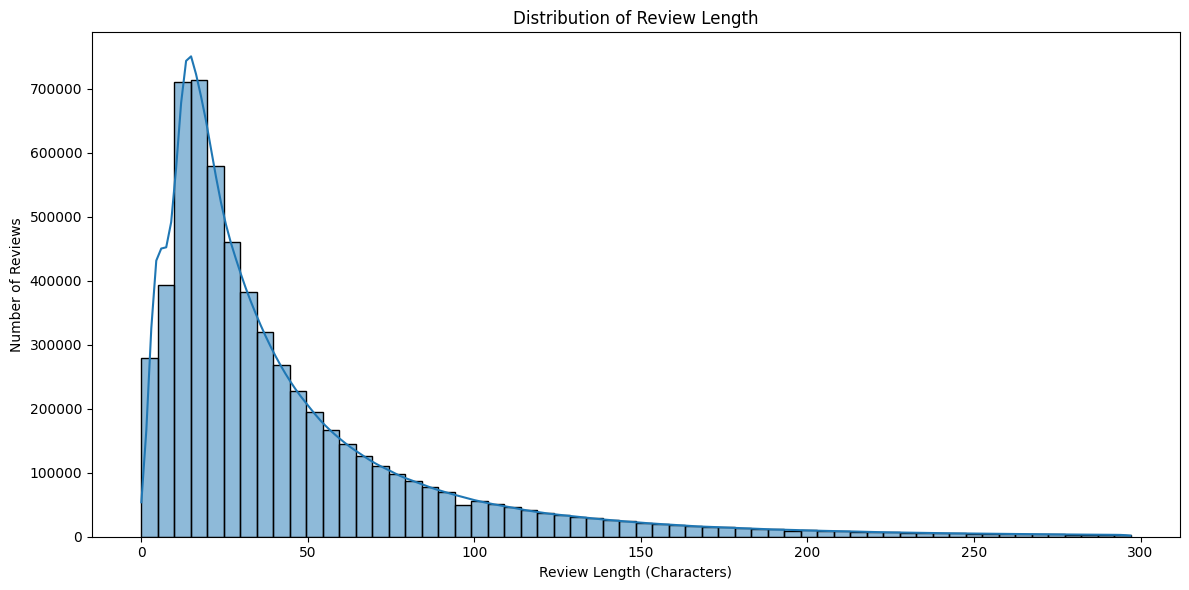

In [24]:
upper_limit = text_df["review_length"].quantile(0.99)

plt.figure(figsize=(12, 6))

sns.histplot(
    text_df.loc[text_df["review_length"] <= upper_limit, "review_length"],
    bins=60,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [25]:
Q1 = text_df["review_length"].quantile(0.25)
Q3 = text_df["review_length"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

outliers = text_df["review_length"] > upper_bound

print(f"Upper Bound: {upper_bound}")
print(f"Outliers: {outliers.sum():,}")
print(f"Outlier Percentage: {outliers.mean() * 100:.2f}%")


empty_reviews = (text_df["review_length"] == 0).sum()

print(f"Empty Reviews: {empty_reviews:,}")
print(f"Percentage: {empty_reviews / len(text_df) * 100:.4f}%")

Upper Bound: 120.0
Outliers: 490,574
Outlier Percentage: 7.97%
Empty Reviews: 637
Percentage: 0.0103%


## A part 5 : Duplicates

In [26]:
# Check duplicate review IDs
duplicate_ids = text_df["id"].duplicated().sum()

unique_ids = text_df["id"].nunique()

total_rows = len(text_df)

print(f"Total Rows: {total_rows:,}")
print(f"Unique Review IDs: {unique_ids:,}")
print(f"Duplicate IDs: {duplicate_ids:,}")
print(f"Duplicate Percentage: {duplicate_ids / total_rows * 100:.4f}%")

Total Rows: 6,156,289
Unique Review IDs: 6,153,060
Duplicate IDs: 3,229
Duplicate Percentage: 0.0525%


In [27]:
# Extract all rows with duplicated IDs
duplicate_df = text_df[
    df["id"].duplicated(keep=False)
].sort_values("id")

# Number of duplicated ID groups
duplicate_id_groups = duplicate_df["id"].nunique()

# Check whether duplicated records are identical
identical_rows = duplicate_df.duplicated().sum()

print(f"Duplicated ID Groups: {duplicate_id_groups:,}")
print(f"Rows with Duplicated IDs: {len(duplicate_df):,}")
print(f"Completely Identical Rows: {identical_rows:,}")

Duplicated ID Groups: 3,226
Rows with Duplicated IDs: 6,455
Completely Identical Rows: 2,925


In [28]:
duplicate_df[
    ["id", "product_id", "rate", "title", "body"]
].head(20)

,id,product_id,rate,title,body
1603315,1002211,65742,3.00,پیشنهاد,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکن...
1603222,1002211,65742,3.00,پیشنهاد,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکن...
1267069,1123478,156134,0.00,کتاب صوتی شازده کوچولو,یکی از مهمترین مزایای کتاب صوتی قابل استفاده ب...
1267067,1123478,156134,0.00,کتاب صوتی شازده کوچولو,یکی از مهمترین مزایای کتاب صوتی قابل استفاده ب...
593999,1153354,68722,5.00,کیفیت عالی اثر,تنها میتونم بگم این کتاب فوق العاده س.\r\nمن ب...
593895,1153354,68722,5.00,کیفیت عالی اثر,تنها میتونم بگم این کتاب فوق العاده س.\r\nمن ب...
1603314,1162097,65742,4.15,فوقلعلاده است!,این یکی از شیرین ترین داشتان هاییهکه خوندم، مث...
1603221,1162097,65742,4.15,فوقلعلاده است!,این یکی از شیرین ترین داشتان هاییهکه خوندم، مث...
930958,1186549,170863,4.75,بسیار,بسیار عالی بود. کیفیت صدا بسیار خوب بود.\r\nپس...
930873,1186549,170863,4.75,بسیار,بسیار عالی بود. کیفیت صدا بسیار خوب بود.\r\nپس...


In [29]:
# Remove completely identical rows temporarily for analysis
distinct_records = duplicate_df.drop_duplicates()

# Count distinct records per ID
records_per_id = distinct_records.groupby("id").size()

# IDs associated with different records
conflicting_ids = records_per_id[records_per_id > 1]

print(f"IDs with Different Records: {len(conflicting_ids):,}")
print(f"IDs with Identical Records Only: {(records_per_id == 1).sum():,}")

IDs with Different Records: 304
IDs with Identical Records Only: 2,922


In [ ]:
# Columns to investigate
check_columns = [
    "product_id",
    "rate",
    "title",
    "body",
    # "recommendation_status",
    "created_at"
]

# Count duplicated IDs with conflicting values per column
for col in check_columns:
    conflicts = (
        duplicate_df.groupby("id")[col]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )

    print(f"{col}: {conflicts:,}")

product_id: 0
rate: 79
title: 85
body: 241


KeyError: 'Column not found: recommendation_status'

In [ ]:
# Select conflicting IDs
sample_conflicting_ids = conflicting_ids.index[:10]

# Display their records
conflict_samples = (
    duplicate_df[
        duplicate_df["id"].isin(sample_conflicting_ids)
    ]
    .sort_values("id")
)

conflict_samples[
    ["id", "product_id", "rate", "title", "body",
     "recommendation_status", "created_at"]
]

,id,product_id,rate,title,body,recommendation_status,created_at
3383370,1271444,82046,3.00,خوب نیست,من 1 بار گرفتم خیلی پوستو سفید میکنه و برق مین...,NaN,25 اسفند 1395
4006917,1271444,82046,3.00,خوب نیست,من 1 بار گرفتم خیلی پوستو سفید میکنه و برق مین...,NaN,25 اسفند 1395
3383369,1542527,82046,2.50,دوست پوست های مستعد آکنه,مشکل پوست های مستعد آکنه اینه که حتی انتخاب نا...,NaN,9 آبان 1396
4006916,1542527,82046,2.50,دوست پوست های مستعد آکنه,مشکل پوست های مستعد آکنه اینه که حتی انتخاب نا...,NaN,9 آبان 1396
4007246,1766600,524441,5.00,ژل حجم دهنده,حتماً پیشنهاد میکنم عالیه فقط در بعضی ها ممکن ...,NaN,5 فروردین 1397
502366,1766600,524441,5.00,ژل حجم دهنده,حتماً پیشنهاد میکنم عالیه فقط در بعضی ها ممکن ...,NaN,5 فروردین 1397
429533,1925710,524441,3.90,استفاده درست حتما پاسخ‌میگیرید,تو کوتاه مدت اثر نداره ولی باید طرز استفاده رو...,NaN,9 تیر 1397
4007245,1925710,524441,3.90,استفاده درست حتما پاسخ‌میگیرید,تو کوتاه مدت اثر نداره ولی باید طرز استفاده رو...,NaN,9 تیر 1397
1523818,2518544,594581,3.00,NaN,خوبه ولی زود تموم میشه,NaN,30 بهمن 1397
2493781,2518544,594581,3.00,NaN,خوبه ولی زود تموم میشه,NaN,30 بهمن 1397


In [ ]:
# Find columns with different values for each duplicated ID
for review_id in sample_conflicting_ids:

    group = text_df[text_df["id"] == review_id]

    different_columns = [
        col for col in text_df.columns
        if group[col].nunique(dropna=False) > 1
    ]

    print(f"\nID: {review_id}")
    print(f"Different Columns: {different_columns}")


ID: 1271444
Different Columns: ['likes']

ID: 1542527
Different Columns: ['dislikes']

ID: 1766600
Different Columns: ['likes']

ID: 1925710
Different Columns: ['likes']

ID: 2518544
Different Columns: ['likes']

ID: 2577115
Different Columns: ['dislikes']

ID: 2722512
Different Columns: ['likes']

ID: 3255644
Different Columns: ['likes']

ID: 4083940
Different Columns: ['likes']

ID: 8200466
Different Columns: ['likes']


In [ ]:
conflict_columns = Counter()

for review_id, group in duplicate_df.groupby("id"):

    different_columns = [
        col for col in df.columns
        if group[col].nunique(dropna=False) > 1
    ]

    if different_columns:
        conflict_columns.update(different_columns)

# Results
conflict_summary = pd.DataFrame(
    conflict_columns.items(),
    columns=["column", "conflicting_id_groups"]
).sort_values(
    "conflicting_id_groups",
    ascending=False
)

conflict_summary

,column,conflicting_id_groups
0,likes,1217
1,dislikes,294
3,body,241
6,review_length,233
4,seller_title,154
5,seller_code,147
9,recommendation_status,101
2,title,85
7,rate,79
8,advantages,41


In [ ]:
engagement_cols = ["likes", "dislikes"]

content_cols = [
    "rate", "title", "body",
    "recommendation_status",
    "advantages", "disadvantages"
]

additional_cols = [
    "seller_title", "seller_code",
    "is_buyer", "true_to_size_rate"
]

grouped = duplicate_df.groupby("id")

engagement_conflict = grouped[engagement_cols].nunique(
    dropna=False
).gt(1).any(axis=1)

content_conflict = grouped[content_cols].nunique(
    dropna=False
).gt(1).any(axis=1)

additional_conflict = grouped[additional_cols].nunique(
    dropna=False
).gt(1).any(axis=1)

summary = pd.DataFrame({
    "Engagement Conflict": engagement_conflict,
    "Content Conflict": content_conflict,
    "Additional Info Conflict": additional_conflict
})

print(summary.sum())

Engagement Conflict         1497
Content Conflict             368
Additional Info Conflict     157
dtype: int64


In [ ]:
# Create a new dataset without exact duplicate rows
df_unique = text_df.drop_duplicates().copy()

print(f"Original rows: {len(text_df):,}")
print(f"New dataset rows: {len(df_unique):,}")
print(f"Removed rows: {len(text_df) - len(df_unique):,}")

Original rows: 6,156,289
New dataset rows: 6,154,971
Removed rows: 1,318


In [ ]:
# Exclude empty review texts for this analysis
valid_reviews = text_df[text_df["body"].notna() & text_df["body"].str.strip().ne("")]

# Detect duplicate review content within the same product
duplicate_reviews = valid_reviews.duplicated(
    subset=["product_id", "body"],
    keep=False
)

duplicate_review_df = valid_reviews[duplicate_reviews].copy()

# Summary
print(f"Valid Reviews: {len(valid_reviews):,}")
print(f"Duplicate Review Rows: {len(duplicate_review_df):,}")
print(
    f"Duplicate Review Groups: "
    f"{duplicate_review_df.groupby(['product_id', 'body']).ngroups:,}"
)
print(
    f"Duplicate Percentage: "
    f"{duplicate_reviews.sum() / len(valid_reviews) * 100:.2f}%"
)

Valid Reviews: 6,155,652
Duplicate Review Rows: 312,284
Duplicate Review Groups: 106,378
Duplicate Percentage: 5.07%


In [ ]:
duplicate_review_df[
    ["id", "product_id", "rate", "title", "body"]
].sort_values(
    ["product_id", "body"]
).head(20)

,id,product_id,rate,title,body
6145540,41820523,7602,4.0,NaN,خوب
6145550,39265460,7602,4.0,NaN,خوب
6145569,35053619,7602,4.0,خوب بود,خوب بود
6145613,27392133,7602,4.0,خوب بود,خوب بود
6145534,45176911,7602,5.0,NaN,خوبه
6145554,33866550,7602,5.0,NaN,خوبه
6145555,33424021,7602,5.0,خوب,عالی
6145597,31080892,7602,5.0,NaN,عالی
6145632,22637568,7602,5.0,دسته پلی استیشن 3,عالی
274280,54515360,12302,5.0,NaN,عالی


In [ ]:
# Columns used to identify an exact duplicate review
fingerprint_cols = [
    col for col in text_df.columns
    if col != "id"
]

# Generate record fingerprints
text_df["fingerprint"] = pd.util.hash_pandas_object(
    text_df[fingerprint_cols],
    index=False
)

# Find duplicate records
duplicate_records = text_df[
    text_df.duplicated(
        subset="fingerprint",
        keep=False
    )
].sort_values("fingerprint")

In [ ]:
len(duplicate_records)

3397

# B

In [ ]:
for i in range(10):

    print(text_df["body"].sample(i+1, random_state=42).iloc[i])

کیفیت مطلوب 
کتاب خیلی بامزه ای هست
من نمیدونم دوستان تا حالا قیچی دستشون نگرفتن هنوز .طبق نظر دوستان خرید کردم ولی اصلا خوش دست و بدرد بخور نیست .این قیچی ها برش کلفت میده یعنی میخاین مورو کات کنید جوری کات میگنه که رده مینداره و بدرد ارایشری نمیخوره .یدونه از همین قیچی ها دارم باهاش کار میکنم همین برند هست ولی زمین تا زیر زمین باهم فرق میکنه و فکر کردم این هم مثل همونه و از نظر مثبت دوستان مطمعن شدم ولی متسفانه بیشتر نظرها کاذب هست و راهنمای نمیکنن تو خرید .
خوبه
خیلی خوبه   
عالیه و بسته بندی بندی و کیفیت بسیار بالا . کاملا سرگرم کننده
رنگ خوبی داره و ۲۴ ساعته است و وقتی میزنی انگار رنگ لبته و خیلی طبیعی عه و خیلی هم نازه
واقعا جنس خوبی داره و کاردبری و کم حجم 
به درد دوستان کوهنورد و کمپی میخوره 
راضی بودم
ساده و سرگرم کننده


In [ ]:
text_stats = pd.DataFrame({
    "total": len(text_df),
    "non_null": text_df[["title", "body"]].count(),
    "unique": text_df[["title", "body"]].nunique(),
    "empty": text_df[["title", "body"]].apply(
        lambda col: col.fillna("").str.strip().eq("").sum()
    )
})

display(text_stats)

,total,non_null,unique,empty
title,6156289,3291227,772293,2866415
body,6156289,6155652,4136257,637


In [ ]:
body_length = text_df["body"].str.len()
short_thresholds = [5, 10, 15, 20]

short_review_stats = pd.DataFrame({
    "count": [
        (body_length <= threshold).sum()
        for threshold in short_thresholds
    ],
    "percentage": [
        (body_length <= threshold).mean() * 100
        for threshold in short_thresholds
    ]
}, index=short_thresholds)

short_review_stats.index.name = "max_length"

display(short_review_stats)

,count,percentage
max_length,,
5,349375,5.675091
10,762953,12.393067
15,1540717,25.026717
20,2224177,36.128535


In [31]:

# ============================================================
# B: DATA PREPARATION
# Persian Text Cleaning, Quality Control & Grouped Split
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display


# ============================================================
# 0. CONFIGURATION
# ============================================================

TARGET_COL = "recommendation_status"

LABEL_CLASSES = [
    "recommended",
    "not_recommended",
    "no_idea"
]

TRAIN_RATIO = 0.80
VALIDATION_RATIO = 0.10
TEST_RATIO = 0.10

RANDOM_STATE = 42

REQUIRED_COLUMNS = [
    "id",
    "product_id",
    "body",
    TARGET_COL
]

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing columns: {missing_columns}")

if not np.isclose(
    TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO,
    1.0
):
    raise ValueError("Split ratios must sum to 1.")

print(f"Original dataset: {len(df):,} rows")


# ============================================================
# B1. CREATE INDEPENDENT WORKING DATAFRAME
# ============================================================

prepared_df = df[REQUIRED_COLUMNS].copy()

original_missing_body = prepared_df["body"].isna().sum()


# ============================================================
# B2. PERSIAN TEXT CLEANING
# ============================================================

# Convert to pandas string type
clean_text = prepared_df["body"].astype("string")

# Unicode normalization
clean_text = clean_text.str.normalize("NFKC")

# Normalize Arabic characters to Persian characters
persian_translation = str.maketrans({
    "ي": "ی",
    "ى": "ی",
    "ك": "ک"
})

clean_text = clean_text.str.translate(
    persian_translation
)

# Remove URLs
clean_text = clean_text.str.replace(
    r"(?i)\b(?:https?://|www\.)\S+",
    " ",
    regex=True
)

# Remove email addresses
clean_text = clean_text.str.replace(
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
    " ",
    regex=True
)

# Remove HTML tags
clean_text = clean_text.str.replace(
    r"<[^>]*>",
    " ",
    regex=True
)

# Remove HTML entities
clean_text = clean_text.str.replace(
    r"&(?:[a-zA-Z]{2,10}|#\d{1,6}|#x[0-9a-fA-F]+);",
    " ",
    regex=True
)

# Remove Arabic diacritics and Tatweel
clean_text = clean_text.str.replace(
    r"[\u064B-\u065F\u0670\u0640]",
    "",
    regex=True
)

# Remove invisible characters and directional marks
# Preserve Persian ZWNJ (\u200c)
clean_text = clean_text.str.replace(
    r"[\u200b\ufeff\u200e\u200f\u202a-\u202e]",
    "",
    regex=True
)

# Normalize spaces around ZWNJ
clean_text = clean_text.str.replace(
    r"[ \t]*\u200c[ \t]*",
    "\u200c",
    regex=True
)

# Replace multiple spaces and line breaks with one space
clean_text = clean_text.str.replace(
    r"\s+",
    " ",
    regex=True
)

# Remove leading and trailing spaces
clean_text = clean_text.str.strip()

# Convert empty strings to missing values
clean_text = clean_text.mask(
    clean_text.eq("")
)

# Add cleaned text
prepared_df["text"] = clean_text

# Remove original body from working dataframe
prepared_df.drop(
    columns=["body"],
    inplace=True
)

print("Persian text cleaning completed.")


# ============================================================
# B3. TEXT QUALITY CONTROL
# ============================================================

text_length = prepared_df["text"].str.len()

total_rows = len(prepared_df)

quality_records = [
    ("Total Reviews", total_rows),

    ("Missing Original Body", original_missing_body),

    (
        "Empty After Cleaning",
        prepared_df["text"].isna().sum()
    ),

    (
        "Valid Reviews",
        prepared_df["text"].notna().sum()
    )
]

# Analyze short reviews using previous A4 thresholds
short_thresholds = [5, 10, 15, 20]

for threshold in short_thresholds:

    count = text_length.le(threshold).fillna(False).sum()

    quality_records.append(
        (f"Reviews <= {threshold} Characters", count)
    )

quality_summary = pd.DataFrame(
    quality_records,
    columns=["metric", "count"]
)

quality_summary["percentage"] = (
    quality_summary["count"] / total_rows * 100
)

print("\nTEXT QUALITY SUMMARY")

display(
    quality_summary.round(2)
)


# Character length statistics
text_length_summary = (
    text_length
    .dropna()
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame("character_length")
)

print("\nCLEANED TEXT LENGTH STATISTICS")

display(
    text_length_summary.round(2)
)


# ============================================================
# B4. PREPARE CLASS LABELS
# ============================================================

# recommendation_status is used as the provisional
# supervised classification target.

status = (
    prepared_df[TARGET_COL]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Identify unexpected labels
unknown_mask = (
    status.notna()
    & ~status.isin(LABEL_CLASSES)
)

unknown_target_values = (
    status[unknown_mask]
    .value_counts()
    .rename_axis("unknown_label")
    .to_frame("count")
)

# Keep only the three known classes.
# Missing and unexpected labels remain unlabeled.
prepared_df["target"] = status.where(
    status.isin(LABEL_CLASSES),
    pd.NA
)

prepared_df.drop(
    columns=[TARGET_COL],
    inplace=True
)

# Target distribution
target_distribution = (
    prepared_df["target"]
    .value_counts(dropna=False)
    .rename_axis("target")
    .to_frame("count")
)

target_distribution["percentage"] = (
    target_distribution["count"] / total_rows * 100
)

print("\nTARGET DISTRIBUTION")

display(
    target_distribution.round(2)
)

print("\nUNEXPECTED TARGET VALUES")

display(unknown_target_values)


# ============================================================
# B5. GROUPED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# Product IDs are used ONLY for grouping.
# They are NOT model input features.

product_ids = (
    prepared_df["product_id"]
    .dropna()
    .unique()
)

if len(product_ids) < 3:
    raise ValueError(
        "Not enough unique products for grouped splitting."
    )

# First: separate Test from Train + Validation
test_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_RATIO,
    random_state=RANDOM_STATE
)

train_val_idx, test_idx = next(
    test_splitter.split(
        np.zeros((len(product_ids), 1)),
        groups=product_ids
    )
)

remaining_products = product_ids[train_val_idx]

test_products = product_ids[test_idx]


# Second: separate Validation from Train
# Validation ratio is calculated relative to remaining groups.

relative_validation_ratio = (
    VALIDATION_RATIO /
    (TRAIN_RATIO + VALIDATION_RATIO)
)

validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=relative_validation_ratio,
    random_state=RANDOM_STATE
)

train_idx, validation_idx = next(
    validation_splitter.split(
        np.zeros((len(remaining_products), 1)),
        groups=remaining_products
    )
)

train_products = remaining_products[train_idx]

validation_products = remaining_products[validation_idx]


# Create product-to-split mapping
product_to_split = {}

product_to_split.update(
    dict.fromkeys(train_products.tolist(), "train")
)

product_to_split.update(
    dict.fromkeys(validation_products.tolist(), "validation")
)

product_to_split.update(
    dict.fromkeys(test_products.tolist(), "test")
)


# Assign every review based on its product ID
prepared_df["split"] = (
    prepared_df["product_id"]
    .map(product_to_split)
)

print("\nGROUPED SPLIT COMPLETED")


# ============================================================
# B6. CREATE MODEL-READY DATASET
# ============================================================

# Only non-empty text and valid product groups
# are included in modeling datasets.

valid_model_mask = (
    prepared_df["text"].notna()
    & prepared_df["split"].notna()
)

model_df = prepared_df.loc[
    valid_model_mask,
    [
        "id",
        "product_id",
        "text",
        "target",
        "split"
    ]
].copy()

if model_df.empty:
    raise ValueError("No valid records available for modeling.")


# ============================================================
# B7. CHECK GROUP LEAKAGE
# ============================================================

split_product_sets = {
    split_name: set(
        model_df.loc[
            model_df["split"] == split_name,
            "product_id"
        ].unique()
    )
    for split_name in ["train", "validation", "test"]
}

train_validation_overlap = (
    split_product_sets["train"]
    & split_product_sets["validation"]
)

train_test_overlap = (
    split_product_sets["train"]
    & split_product_sets["test"]
)

validation_test_overlap = (
    split_product_sets["validation"]
    & split_product_sets["test"]
)

if (
    train_validation_overlap
    or train_test_overlap
    or validation_test_overlap
):
    raise AssertionError(
        "Product leakage detected between splits!"
    )

print("Group leakage check: PASSED")


# ============================================================
# B8. SPLIT SUMMARY
# ============================================================

split_summary_records = []

for split_name in ["train", "validation", "test"]:

    part = model_df[
        model_df["split"] == split_name
    ]

    split_summary_records.append({

        "split": split_name,

        "reviews": len(part),

        "review_percentage": (
            len(part) / len(model_df) * 100
        ),

        "unique_products": (
            part["product_id"].nunique()
        ),

        "labeled_reviews": (
            part["target"].notna().sum()
        ),

        "unlabeled_reviews": (
            part["target"].isna().sum()
        )
    })

split_summary = pd.DataFrame(
    split_summary_records
).set_index("split")

print("\nFINAL SPLIT SUMMARY")

display(
    split_summary.round(2)
)


# ============================================================
# B9. LABEL DISTRIBUTION IN EACH SPLIT
# ============================================================

labeled_model_df = model_df[
    model_df["target"].notna()
]

label_counts = pd.crosstab(
    labeled_model_df["split"],
    labeled_model_df["target"]
).reindex(
    ["train", "validation", "test"],
    fill_value=0
)

label_percentages = (
    label_counts
    .div(label_counts.sum(axis=1), axis=0)
    * 100
).fillna(0)

print("\nLABEL COUNTS BY SPLIT")

display(label_counts)

print("\nLABEL PERCENTAGES BY SPLIT")

display(label_percentages.round(2))


# ============================================================
# B10. CREATE SUPERVISED AND SEMI-SUPERVISED DATASETS
# ============================================================

# Supervised training data
train_labeled = model_df[
    (model_df["split"] == "train")
    & model_df["target"].notna()
].copy()

# Validation data
validation_labeled = model_df[
    (model_df["split"] == "validation")
    & model_df["target"].notna()
].copy()

# Final test data
test_labeled = model_df[
    (model_df["split"] == "test")
    & model_df["target"].notna()
].copy()

# Unlabeled training data for later semi-supervised learning
train_unlabeled = model_df[
    (model_df["split"] == "train")
    & model_df["target"].isna()
].copy()

# Optional held-out unlabeled data
validation_unlabeled = model_df[
    (model_df["split"] == "validation")
    & model_df["target"].isna()
].copy()

test_unlabeled = model_df[
    (model_df["split"] == "test")
    & model_df["target"].isna()
].copy()


# ============================================================
# B11. FINAL MODEL INPUTS
# ============================================================

# Only body-derived text is used as model input.
# product_id, id and target are not text features.

X_train = train_labeled["text"].reset_index(drop=True)
y_train = train_labeled["target"].reset_index(drop=True)

X_validation = (
    validation_labeled["text"].reset_index(drop=True)
)

y_validation = (
    validation_labeled["target"].reset_index(drop=True)
)

X_test = test_labeled["text"].reset_index(drop=True)

y_test = test_labeled["target"].reset_index(drop=True)

# Unlabeled text for semi-supervised methods
X_unlabeled_train = (
    train_unlabeled["text"].reset_index(drop=True)
)


# ============================================================
# B12. FINAL VALIDATION
# ============================================================

assert len(X_train) == len(y_train)

assert len(X_validation) == len(y_validation)

assert len(X_test) == len(y_test)

assert X_train.notna().all()
assert X_validation.notna().all()
assert X_test.notna().all()

assert y_train.notna().all()
assert y_validation.notna().all()
assert y_test.notna().all()

print("\n" + "=" * 55)
print("DATA PREPARATION COMPLETED SUCCESSFULLY")
print("=" * 55)

print(f"Train labeled:       {len(X_train):,}")
print(f"Validation labeled:  {len(X_validation):,}")
print(f"Test labeled:        {len(X_test):,}")
print(f"Train unlabeled:     {len(X_unlabeled_train):,}")

print(
    f"Rows without text or product group: "
    f"{len(prepared_df) - len(model_df):,}"
)

print(
    f"Products in Train:      {len(split_product_sets['train']):,}"
)

print(
    f"Products in Validation: {len(split_product_sets['validation']):,}"
)

print(
    f"Products in Test:       {len(split_product_sets['test']):,}"
)

print("\nAll product groups are isolated between splits.")
print("Original df remains unchanged.")


Original dataset: 6,156,289 rows


ArrowInvalid: Invalid regular expression: invalid escape sequence: \u